<a href="https://colab.research.google.com/github/ayatahiri2005-hash/tp3-vision-par-ordinateur/blob/main/part_two.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Exercice 1:**

In [ ]:
!pip install opencv-python numpy matplotlib

In [ ]:
from google.colab import files

uploaded = files.upload()

Saving image.jpg to image.jpg


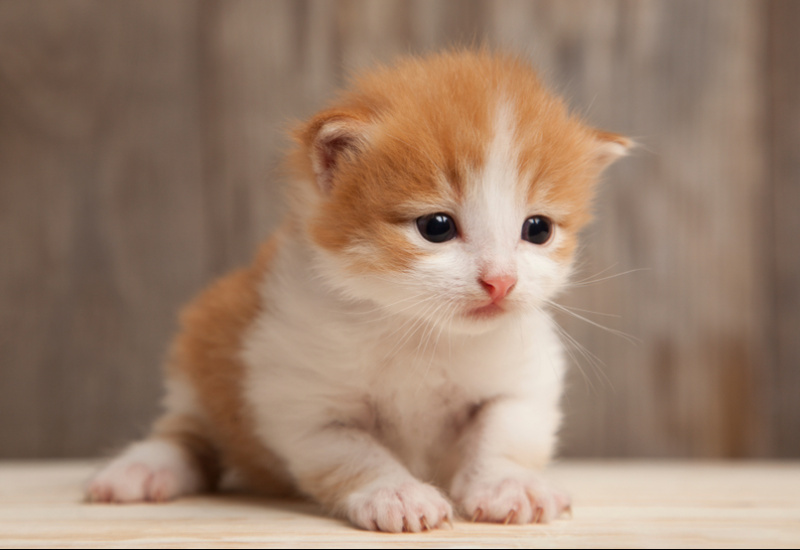

In [ ]:
import cv2
from google.colab.patches import cv2_imshow

# Lire une image
img = cv2.imread('image.jpg')

# Afficher l'image dans une fenêtre
cv2_imshow(img)

Capture de l'image ‼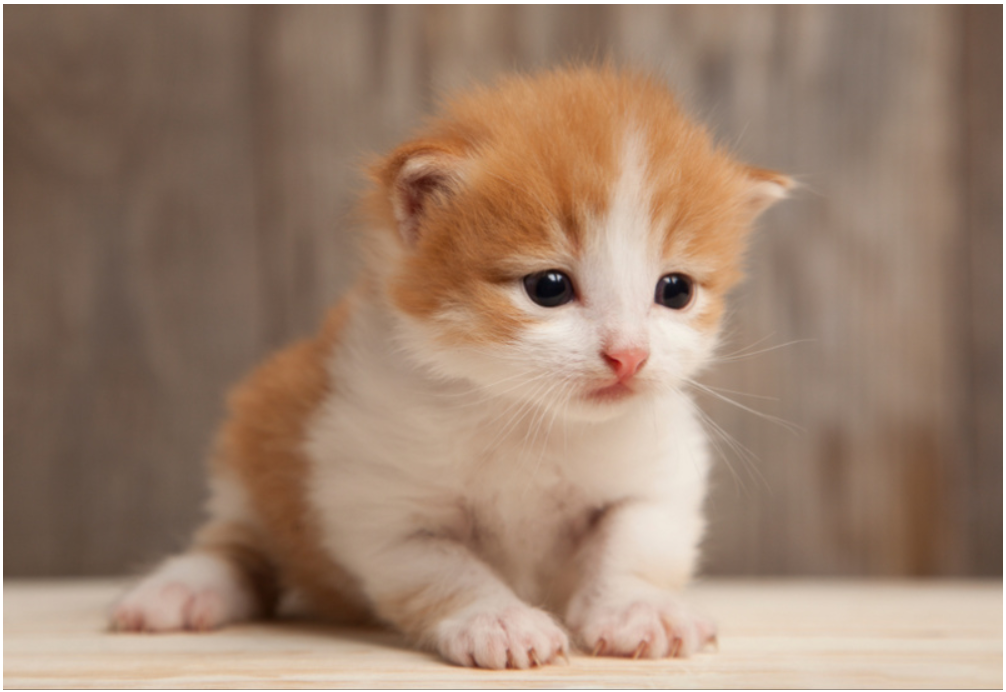

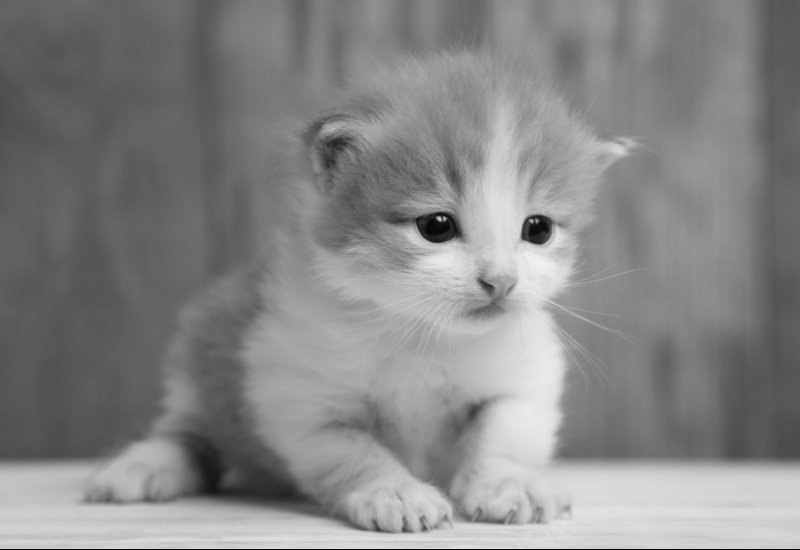

In [ ]:
# Conversion en niveaux de gris
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

cv2_imshow(gray)

Capture du resultat:
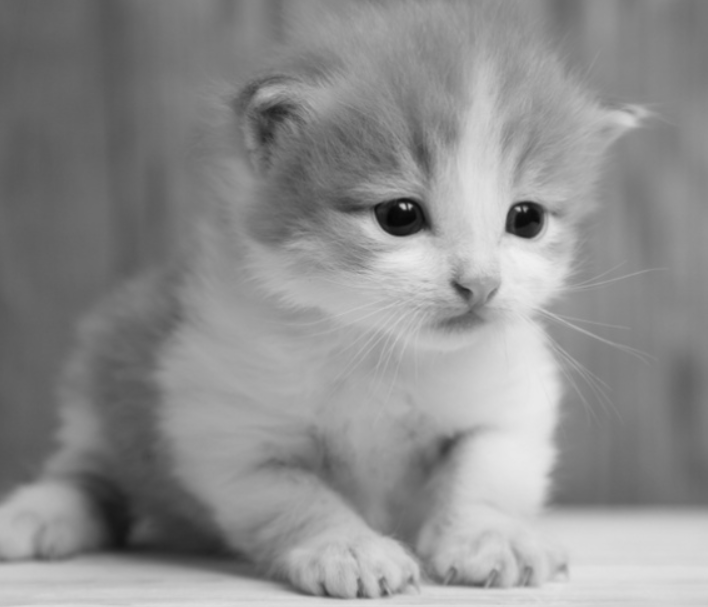

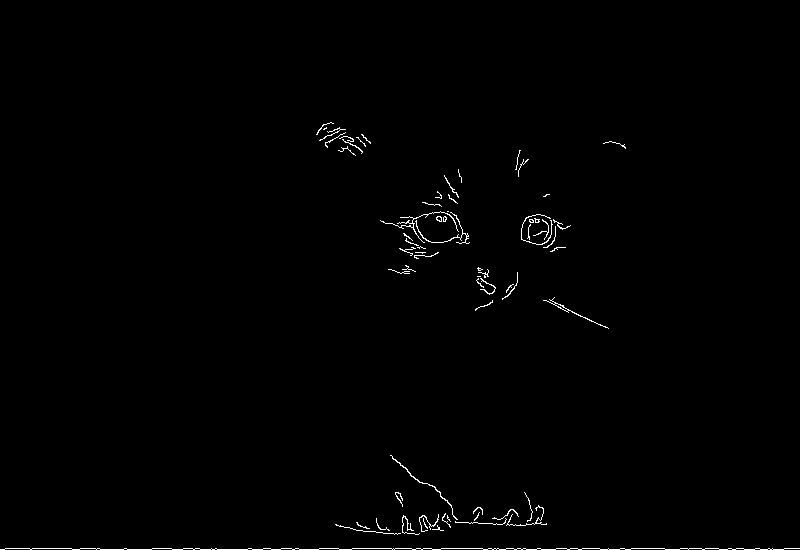

In [ ]:
# Détection des contours avec l'algorithme de Canny
edges = cv2.Canny(img, 100, 200)

cv2_imshow(edges)

Capture du résultat:
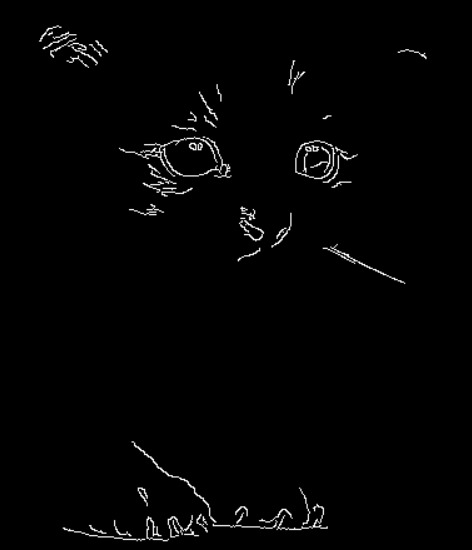

**Question 1:**
La matrice retournée par OpenCV représente les pixels de l'image sous forme de valeurs numériques. Une image couleur possède généralement trois canaux (BGR), tandis qu'une image en niveaux de gris possède un seul canal.
**Question 2:**
On convertit une image en niveaux de gris pour réduire la quantité de données à traiter, simplifier les calculs et faciliter les opérations basées sur les variations d'intensité, comme la détection des contours.
**Question 3: **
Le filtre gaussien est utilisé pour réduire le bruit et lisser l'image avant son traitement. Il permet d'obtenir une détection des contours plus propre et de limiter les fausses détections provoquées par les variations indésirables des pixels.

**Exercice 3:**

In [ ]:
!pip install --no-build-isolation -U 'git+https://github.com/facebookresearch/detectron2.git'

  Cloning https://github.com/facebookresearch/detectron2.git to /tmp/pip-req-build-1n_gncu2
  Running command git clone --filter=blob:none --quiet https://github.com/facebookresearch/detectron2.git /tmp/pip-req-build-1n_gncu2
  Resolved https://github.com/facebookresearch/detectron2.git to commit 247691a1c292654867deb35cabb27f18d75a1363
  Preparing metadata (pyproject.toml) ... done
  Preparing metadata (pyproject.toml) ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.1/2.1 MB 33.3 MB/s  0:00:00
  Created wheel for detectron2: filename=detectron2-0.6-cp313-cp313-linux_x86_64.whl size=7030237 sha256=854822c4d2fed90f894ac4efb22273c9575108145c233d00ea0d66f9d0cbe371
  Stored in directory: /tmp/pip-ephem-wheel-cache-641d9edh/wheels/d9/ed/56/4ffdb2ce244e0d6ed6c0916db7f7a74254f74435fea7142143
  Created wheel for fvcore: filename=fvcore-0.1.5.post20221221-py3-none-any.whl size=61447 sha256=8452e2f1bf94f692cb67b87b18170e4c0c0f6636a12c0c711b31

In [ ]:
import cv2
import torch
from detectron2.engine import DefaultPredictor
from detectron2.config import get_cfg
from detectron2 import model_zoo
from detectron2.utils.visualizer import Visualizer
from detectron2.data import MetadataCatalog
from google.colab.patches import cv2_imshow

/usr/local/lib/python3.13/dist-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/detectron2/model_zoo/model_zoo.py:4: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources


In [ ]:
CONFIG = "COCO-InstanceSegmentation/mask_rcnn_R_50_FPN_3x.yaml"
cfg = get_cfg()
cfg.merge_from_file(model_zoo.get_config_file(CONFIG))
cfg.MODEL.ROI_HEADS.SCORE_THRESH_TEST = 0.5  # Seuil de confiance à 50%
cfg.MODEL.WEIGHTS = model_zoo.get_checkpoint_url(CONFIG)
cfg.MODEL.DEVICE = "cpu"  # Force l'utilisation du processeur
predictor = DefaultPredictor(cfg)

model_final_f10217.pkl: 178MB [00:01, 177MB/s]                           


In [ ]:
img = cv2.imread("image.jpg")
outputs = predictor(img)

/usr/local/lib/python3.13/dist-packages/torch/functional.py:504: UserWarning: torch.meshgrid: in an upcoming release, it will be required to pass the indexing argument. (Triggered internally at /__w/pytorch/pytorch/aten/src/ATen/native/TensorShape.cpp:4221.)
  return _VF.meshgrid(tensors, **kwargs)  # type: ignore[attr-defined]
W1114 20:07:47.908000 435 torch/fx/_symbolic_trace.py:57] is_fx_tracing will return true for both fx.symbolic_trace and torch.export. Please use is_fx_tracing_symbolic_tracing() for specifically fx.symbolic_trace or torch.compiler.is_compiling() for specifically torch.export/compile.


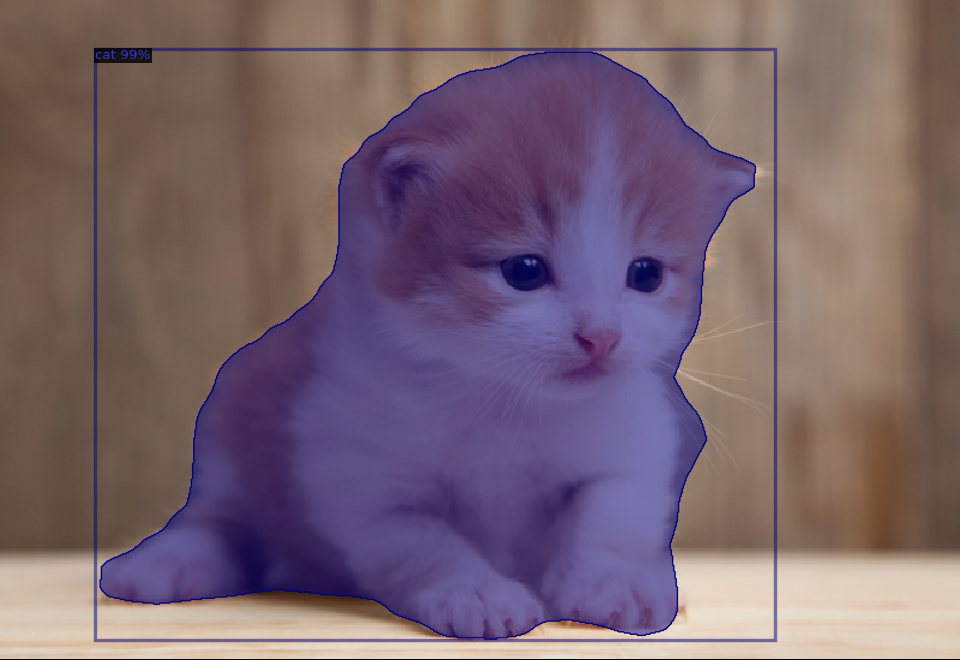

In [ ]:
v = Visualizer(img[:, :, ::-1], MetadataCatalog.get(cfg.DATASETS.TRAIN[0]), scale=1.2)
out = v.draw_instance_predictions(outputs["instances"].to("cpu"))
cv2_imshow(out.get_image()[:, :, ::-1])

Capture du resultat:
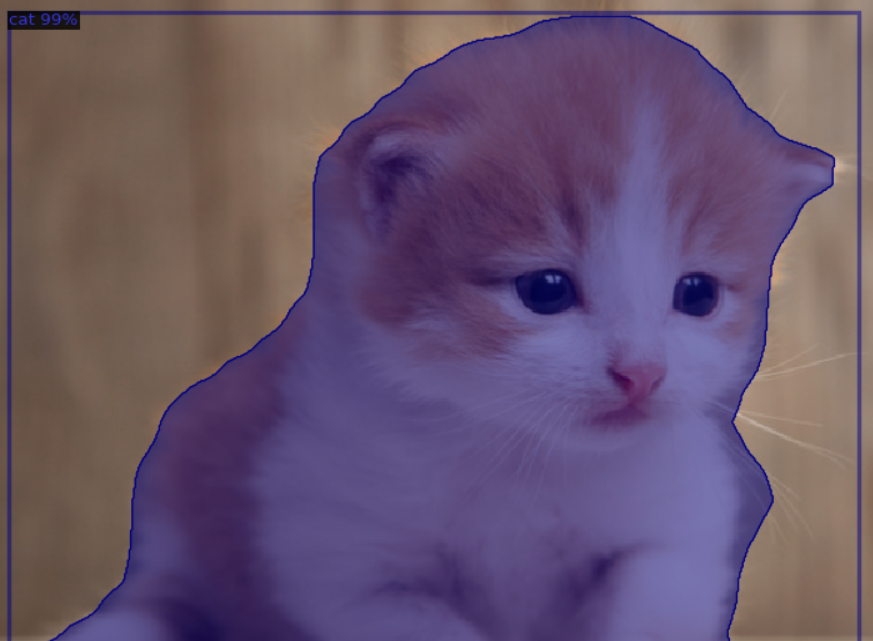

1. Quels objets ont été détectés ?
Un seul objet a été détecté : un chat avec un score de confiance très élevé de 99%.   
2. Modifiez le seuil SCORE_THRESH_TEST et observez l’effet sur la détection.
Effet d'une modification du seuil :
Puisque le score de confiance actuel du chat est de 99%, si on augmente le seuil SCORE_THRESH_TEST, le chat sera toujours détecté et affiché, car 99% est supérieur à ces seuils.   
En revanche, si on augmente le seuil au-delà de 0.99, la détection disparaîtrait car le modèle exigerait un niveau de certitude supérieur à ce que le score fournit. Si le seuil est abaissé, la détection reste inchangée puisque le score est déjà au maximum de la certitude standard.

**Exercice 7:**

In [ ]:
!pip install ultralytics

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 28.6 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4/4 [ultralytics]


In [ ]:
import os
from ultralytics import YOLO
import cv2
from google.colab.patches import cv2_imshow

model = YOLO("yolov8n.pt")

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings


In [ ]:
from google.colab import files

uploaded = files.upload()

Saving image2.jpg to image2.jpg



image 1/1 /content/image2.jpg: 448x640 8 persons, 409.3ms
Speed: 16.7ms preprocess, 409.3ms inference, 1.3ms postprocess per image at shape (1, 3, 448, 640)


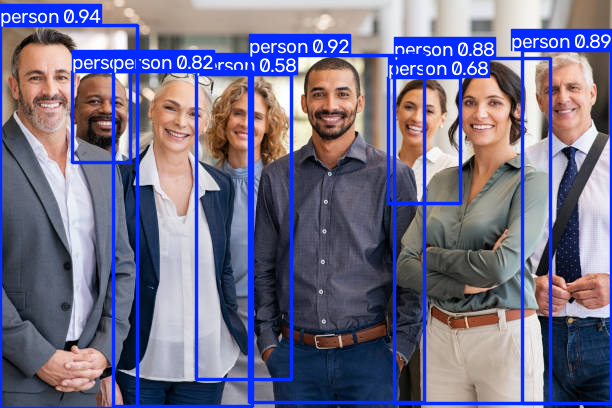

In [ ]:
image_path = "image2.jpg"
if not os.path.exists(image_path):
    print(f"'{image_path}'")

try:
    # Exécution de la détection d'objets
    results = model(image_path, conf=0.5)
    # Affichage du résultat tracé sur l'image
    cv2_imshow(results[0].plot())
except Exception as e:
    print("Erreur lors de la détection :", e)

Capture du résultat:
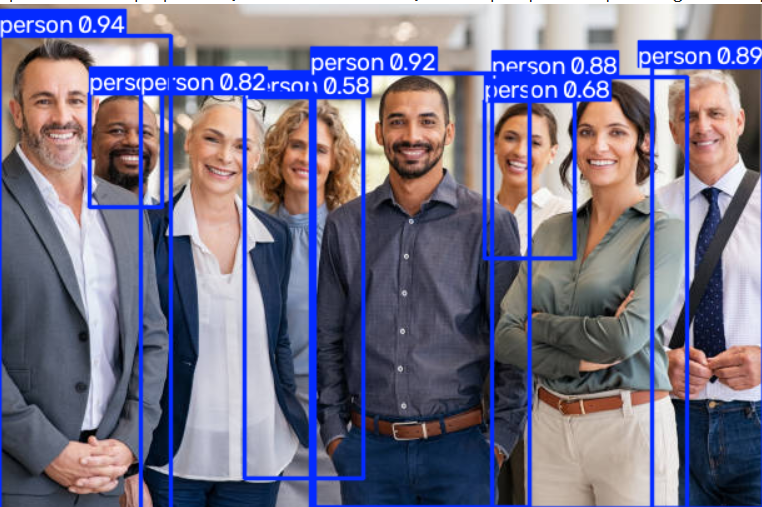

1. Comparez le temps d’inférence de YOLOv8n et de Mask R-CNN sur la même image (utilisez time.time()).

In [ ]:
import time

start_time = time.time()
results = model(image_path, conf=0.5)
end_time = time.time()

print(f"Temps d'inférence YOLOv8n : {end_time - start_time:.4f} secondes")


image 1/1 /content/image2.jpg: 448x640 8 persons, 169.8ms
Speed: 3.5ms preprocess, 169.8ms inference, 1.7ms postprocess per image at shape (1, 3, 448, 640)
Temps d'inférence YOLOv8n : 0.1918 secondes


**Comparaison :**
YOLOv8n est un modèle dit one-stage extrêmement rapide, ce qui le rend idéal pour le temps réel.
Mask R-CNN est un modèle two-stage plus lourd et complexe (avec l'extraction de régions et la génération de masques précis), ce qui engendre un temps d'inférence nettement plus élevé.

2. YOLO fournit-il des masques de segmentation ? Testez yolov8n-seg.pt.
Oui, YOLO fournit également des masques de segmentation d'instances à condition d'utiliser une variante dédiée (terminant par -seg).


image 1/1 /content/image2.jpg: 448x640 8 persons, 1 tie, 179.4ms
Speed: 3.0ms preprocess, 179.4ms inference, 19.9ms postprocess per image at shape (1, 3, 448, 640)


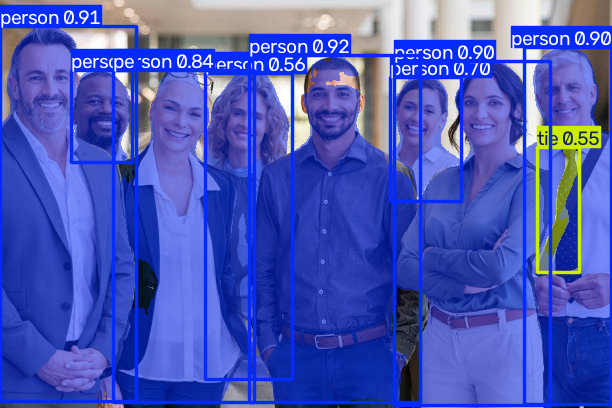

In [ ]:
model_seg = YOLO("yolov8n-seg.pt")
results_seg = model_seg(image_path, conf=0.5)
cv2_imshow(results_seg[0].plot())

Capture du resultat:
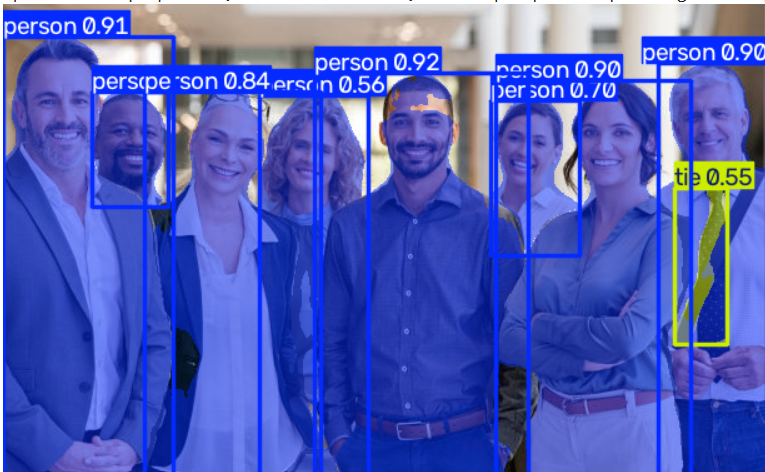

3. Dans quels cas préférer chaque modèle ?
Préférer YOLO (YOLOv8 / YOLOv8-seg) lorsque :
on a besoin de performances en temps réel (flux vidéo de caméras, vidéos de surveillance,..).
Les ressources matérielles sont limitées (appareils mobiles, edge devices, GPU).

Préférer Mask R-CNN lorsque :
La précision chirurgicale des masques de segmentation est la priorité absolue (ex: imagerie médicale, analyse scientifique..).
Le temps de traitement par image importe peu (analyse de photos fixes par lots hors ligne).